In [1]:
import numpyro

numpyro.set_host_device_count(4)
import jax
import jax.numpy as jnp
import arviz as az
import xarray
from scipy.stats import qmc
from ipywidgets import interact, IntSlider
import matplotlib.pyplot as plt

In [2]:
from HSA_GTMo_C_004_numpyro import (
    generate_synthetic_data,
    calculate_partial_pressures,
    TRUE_PARAMS,
)
from HSA_Mo_D_001_numpyro import run_inference, predict, sample_prior

In [3]:
ts = jnp.linspace(0, 12, 10, endpoint=True)

In [4]:
T_range = jnp.array([450, 600])
p_range = jnp.array([3, 9])
c2h_range = jnp.array([0.2, 4])
c2m_range = jnp.array([0.5, 1000])
c2w_range = jnp.array([0.5, 1000])
c2i_range = jnp.array([0.05, 1])

n_obs = 98
sampler = qmc.LatinHypercube(d=6)
sample = sampler.random(n=n_obs)

# Scale samples to the appropriate ranges
T_lhs = qmc.scale(sample[:, 0:1], T_range[0], T_range[1])
p_lhs = qmc.scale(sample[:, 1:2], p_range[0], p_range[1])
c2h_lhs = qmc.scale(sample[:, 2:3], c2h_range[0], c2h_range[1])
c2m_lhs = qmc.scale(sample[:, 3:4], c2m_range[0], c2m_range[1])
c2w_lhs = qmc.scale(sample[:, 4:5], c2w_range[0], c2w_range[1])
c2i_lhs = qmc.scale(sample[:, 5:6], c2i_range[0], c2i_range[1])

proposals = jnp.column_stack([T_lhs, p_lhs, c2h_lhs, c2m_lhs, c2w_lhs, c2i_lhs])
print(proposals.shape)

(98, 6)


In [5]:
Ts = proposals[:, 0].reshape(-1, 1)
ps = proposals[:, 1].reshape(-1, 1)
c2hs = proposals[:, 2].reshape(-1, 1)
c2ms = proposals[:, 3].reshape(-1, 1)
c2ws = proposals[:, 4].reshape(-1, 1)
c2is = proposals[:, 5].reshape(-1, 1)
pi = calculate_partial_pressures(ps, c2hs, c2ms, c2ws, c2is)

display(pi.shape)

(98, 5)

In [6]:
T_obs, pi_obs, r_obs = generate_synthetic_data(Ts, ps, c2hs, c2ms, c2ws, c2is, 0.01)
print(T_obs.shape)
print(r_obs.shape)

(98, 1)
(10, 98, 1, 1)


In [7]:
prior_idata = sample_prior()
r_prior = predict(prior_idata, T_obs, pi_obs, key="prior")
display(r_prior.shape)

(10, 98, 1, 25)

In [8]:
@interact(
    i=IntSlider(
        min=0,
        max=r_obs.shape[1] - 1,
        step=1,
        value=0,
        description="Observation Index",
    )
)
def interactive(i):
    plt.plot(r_obs[:, i, 0, 0], "ro", label="Observed data")
    plt.plot(r_prior.mean(axis=3)[:, i, 0], label="Predicted data")
    plt.fill_between(
        jnp.arange(r_prior.shape[0]),
        jnp.quantile(r_prior[:, i, 0, :], 0.05, axis=1),
        jnp.quantile(r_prior[:, i, 0, :], 0.95, axis=1),
        color="gray",
        alpha=0.5,
        label="90% credible interval",
    )

interactive(children=(IntSlider(value=0, description='Observation Index', max=97), Output()), _dom_classes=('w…

In [9]:
post_idata = run_inference(T_obs, pi_obs, r_obs, progressbar=True)

Starting MCMC: 4 chains × (1000 warmup + 4000 samples)


  0%|          | 0/5000 [00:00<?, ?it/s]

  0%|          | 0/5000 [00:00<?, ?it/s]

  0%|          | 0/5000 [00:00<?, ?it/s]

  0%|          | 0/5000 [00:00<?, ?it/s]

MCMC sampling completed successfully!


In [10]:
r_post = predict(post_idata, T_obs, pi_obs, key="posterior")

In [ ]:
@interact(
    i=IntSlider(
        min=0,
        max=r_obs.shape[1] - 1,
        step=1,
        value=0,
        description="Observation Index",
    )
)
def interactive(i):
    plt.plot(r_obs[:, i, 0, 0], "ro", label="Observed data")
    plt.plot(r_post.mean(axis=3)[:, i, 0], label="Predicted data")
    plt.fill_between(
        jnp.arange(r_post.shape[0]),
        jnp.quantile(r_post[:, i, 0, :], 0.05, axis=1),
        jnp.quantile(r_post[:, i, 0, :], 0.95, axis=1),
        color="gray",
        alpha=0.5,
        label="90% credible interval",
    )

interactive(children=(IntSlider(value=0, description='Observation Index', max=97), Output()), _dom_classes=('w…

In [12]:
az.summary(post_idata)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Ea_deact[0],120434.242,2101.623,116543.969,124376.500,18.691,18.914,12693.0,10160.0,1.0
Ea_k[0],77434.367,62.487,77313.336,77548.234,0.532,0.461,13777.0,12390.0,1.0
k0[0],0.000,0.000,0.000,0.000,0.000,0.000,13108.0,11119.0,1.0
k_deact[0],0.000,0.000,0.000,0.000,0.000,0.000,11864.0,10012.0,1.0
n_deact[0],4.813,0.161,4.502,5.103,0.001,0.001,12354.0,10020.0,1.0
...,...,...,...,...,...,...,...,...,...
t_Ea_deact,0.879,0.017,0.846,0.911,0.000,0.000,12693.0,10160.0,1.0
t_Ea_k,0.437,0.001,0.436,0.439,0.000,0.000,13777.0,12390.0,1.0
t_k0,1.239,0.002,1.236,1.243,0.000,0.000,13108.0,11119.0,1.0
t_k_deact,-0.711,0.032,-0.769,-0.650,0.000,0.000,11864.0,10012.0,1.0


KeyboardInterrupt: 

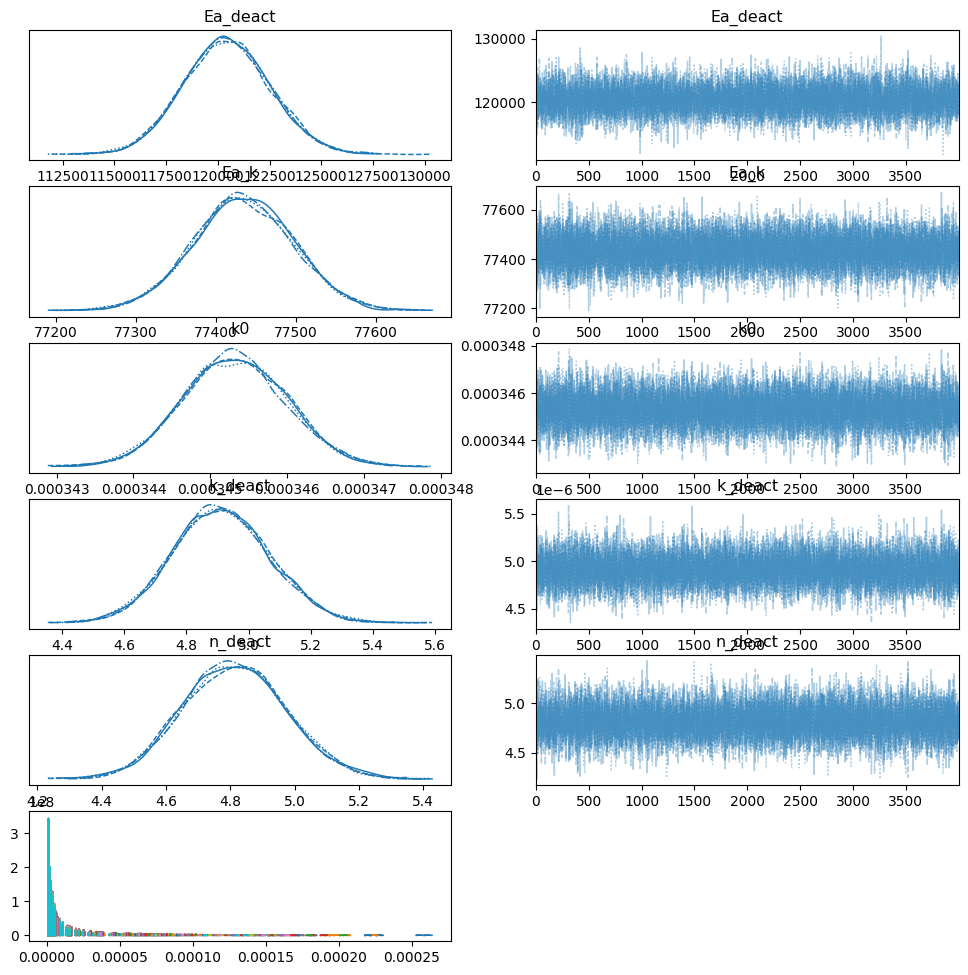

In [13]:
az.plot_trace(post_idata, var)